# 06 · Validación en contextos simulados
**Proyecto integrador — Lector de Facturas** · Sebastián Rojas y Jesús López

Aplica el **Workshop S5 (Validación en contextos reales o simulados)** al modelo final «resumen contable», con la configuración de `configs/definitivo.json` fija **antes** de leer cualquier documento:

| Sección | Pregunta | Concepto de la semana 5 |
|---|---|---|
| 2 | ¿Qué resultado es aceptable? | Criterios y umbrales definidos antes de ejecutar |
| 3–4 | ¿Funciona con documentos que nadie miró al construirlo? | Generalización, evaluación con incertidumbre |
| 5 | ¿Cuántas facturas salen completas y cuánto cuesta revisar? | Métricas del dominio y costo del error |
| 6 | ¿Hasta qué nivel de degradación sigue siendo útil? | Simulación de escenarios críticos (pruebas de estrés) |
| 7 | ¿A quién le funciona peor? | Detección de sesgo por subgrupo |
| 8 | ¿Cómo pasaría a uso real? | Offline → simulación → sombra → piloto → monitoreo |

El código reutilizable está en [`src/validation.py`](../src/validation.py).

## 1. Configuración

In [1]:
# ===== Configuración común de los notebooks 01–06 =====
# En Colab no hace falta clonar nada: se descarga el código de GitHub y se registra su commit.
USAR_CODIGO_LOCAL = False  # True si abres Jupyter dentro de un clon local del repositorio
CODIGO_LOCAL = ''          # Opcional: ruta del clon local (por defecto, la carpeta padre de notebooks/)
USAR_DRIVE = False         # True: datos, pesos, caché OCR y resultados quedan en Google Drive (los notebooks no repiten descargas ni OCR)
DESCARGAR_SI_FALTAN = True
DATOS_MANUAL = ''          # Opcional: ruta a data/raw existente en Drive o Colab
REPOSITORIO = 'Jesusl2202/Document-Scanner'
RAMA = 'main'
SEED = 42

from pathlib import Path
import os, sys, json, subprocess, shutil, hashlib, zipfile, io, urllib.request


def comando(args, cwd=None, mostrar_error=True):
    """Ejecuta un comando y muestra la salida solo si falla."""
    r = subprocess.run(list(map(str, args)), cwd=cwd, capture_output=True, text=True)
    if r.returncode:
        if mostrar_error:
            print(r.stdout[-3000:]); print(r.stderr[-3000:])
        r.check_returncode()
    return r.stdout + r.stderr


# 1) Carpeta de trabajo (fuera de Git)
if USAR_CODIGO_LOCAL:
    CODIGO = Path(CODIGO_LOCAL) if CODIGO_LOCAL else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
    TRABAJO = CODIGO / 'outputs/experimentos'
elif USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    TRABAJO = Path('/content/drive/MyDrive/Lector_Facturas_Experimentos')
else:
    TRABAJO = Path('/content/Lector_Facturas_Experimentos')
TRABAJO.mkdir(parents=True, exist_ok=True)
SALIDAS = TRABAJO / 'notebooks'
SALIDAS.mkdir(parents=True, exist_ok=True)

# 2) Código del repositorio: se descarga el commit exacto y se registra
if USAR_CODIGO_LOCAL:
    REVISION = {'modo': 'local', 'ruta': str(CODIGO)}
else:
    pedido = urllib.request.Request(f'https://api.github.com/repos/{REPOSITORIO}/commits/{RAMA}', headers={'User-Agent': 'lector-facturas'})
    with urllib.request.urlopen(pedido, timeout=60) as respuesta:
        commit = json.load(respuesta)['sha']
    CODIGO = TRABAJO / f'codigo_{commit[:7]}'
    if not (CODIGO / 'src/lector_facturas/consensus.py').exists():
        with urllib.request.urlopen(f'https://codeload.github.com/{REPOSITORIO}/zip/{commit}', timeout=120) as respuesta:
            blob = respuesta.read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            for nombre in z.namelist():
                relativo = '/'.join(nombre.split('/')[1:])
                if not relativo or nombre.endswith('/'):
                    continue
                destino = (CODIGO / relativo).resolve()
                if not destino.is_relative_to(CODIGO.resolve()):
                    raise ValueError('Ruta no permitida dentro del ZIP')
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(z.read(nombre))
    REVISION = {'repositorio': REPOSITORIO, 'rama': RAMA, 'commit': commit}
assert (CODIGO / 'src/lector_facturas/consensus.py').exists(), 'No se encontró el código del lector.'
RAIZ = CODIGO
print('Código:', REVISION)

# 3) Tesseract y bibliotecas
if shutil.which('apt-get') and not shutil.which('tesseract'):
    print('Instalando Tesseract...')
    comando(['apt-get', 'update', '-qq'])
    comando(['apt-get', 'install', '-y', '-qq', 'tesseract-ocr'])
assert shutil.which('tesseract'), 'No se encontró Tesseract. Usa Google Colab con CPU o instálalo en tu equipo.'
comando([sys.executable, '-m', 'pip', 'install', '-q', '-r', CODIGO / 'requirements.txt'])
sys.path.insert(0, str(CODIGO / 'src'))
for modulo in list(sys.modules):
    if modulo == 'lector_facturas' or modulo.startswith('lector_facturas.'):
        del sys.modules[modulo]

# 4) Modelo: configuración definitiva + pesos Tesseract fijados por SHA-256 (fast, best y español)
from lector_facturas import frozen_runtime
RAW_CONFIG = json.loads((CODIGO / 'configs/definitivo.json').read_text(encoding='utf-8'))
assert hasattr(frozen_runtime, 'bind_models') and RAW_CONFIG.get('observed_accounting'), (
    'El código descargado no corresponde al modelo «resumen contable» (configs/definitivo.json). '
    'Revisa REPOSITORIO y RAMA, o usa USAR_CODIGO_LOCAL=True dentro de un clon del repositorio.')
RAW_CONFIG['seed'] = SEED
CONFIG = frozen_runtime.bind_models(RAW_CONFIG, TRABAJO / 'modelos')
VISTAS_MODELO = len(CONFIG['ocr']['ensemble_views'])
print(comando(['tesseract', '--version']).splitlines()[0], f'| {VISTAS_MODELO} vistas OCR + hasta',
      CONFIG['ocr']['adaptive_rescue']['max_views'], 'de rescate')

# 5) Datos: se buscan por contenido y se descargan si faltan
candidatos = [Path(DATOS_MANUAL)] if DATOS_MANUAL else [
    Path('/content/Document-Scanner/data/raw'), TRABAJO / 'data/raw']
DATOS = next((p for p in candidatos if p.exists()), candidatos[-1])
DATOS.mkdir(parents=True, exist_ok=True)


def localizar():
    """Encuentra la raíz de SROIE y de WildReceipt por su contenido, no por el nombre de la carpeta."""
    sroie = next((p.parent.parent for p in DATOS.rglob('entities') if p.is_dir() and p.parent.name == 'train'
                  and (p.parent / 'img').exists() and (p.parent / 'box').exists()), None)
    wild = next((p.parent for p in DATOS.rglob('class_list.txt') if (p.parent / 'train.txt').exists() and (p.parent / 'test.txt').exists()), None)
    return sroie, wild


SROIE, WILD = localizar()
for nombre, ruta in [('sroie', SROIE), ('wildreceipt', WILD)]:
    if ruta is None and DESCARGAR_SI_FALTAN:
        print('Descargando', nombre, '...', flush=True)
        try:
            print(comando([sys.executable, CODIGO / 'scripts/download_data.py', nombre, '--out', DATOS], mostrar_error=False))
        except subprocess.CalledProcessError:
            print(f'No se pudo descargar {nombre}. Descárgalo a mano en {DATOS} o indica DATOS_MANUAL (ver data/raw/README.md).')
SROIE, WILD = localizar()
print('SROIE:      ', SROIE or 'NO ENCONTRADO')
print('WildReceipt:', WILD or 'NO ENCONTRADO')
assert SROIE and WILD, 'Faltan datasets: revisa data/raw/README.md.'

# 6) Manifiesto con la partición del proyecto (train / validation / test / quarantine)
from lector_facturas.datasets import prepare
FILAS = prepare(SROIE, WILD, SALIDAS / 'preparados', RAW_CONFIG)
REVISADOS = json.loads((CODIGO / 'configs/documentos_revisados.json').read_text(encoding='utf-8'))
print('Documentos en el manifiesto:', len(FILAS), '| documentos ya revisados en el desarrollo:', len(REVISADOS))

Código: {'modo': 'local', 'ruta': '/home/runner/work/Document-Scanner/Document-Scanner'}


tesseract 5.3.4 | 10 vistas OCR + hasta 2 de rescate
SROIE:       /home/runner/work/Document-Scanner/Document-Scanner/data/raw/sroie_distribution/SROIE2019
WildReceipt: /home/runner/work/Document-Scanner/Document-Scanner/data/raw/wildreceipt


Documentos en el manifiesto: 2712 | documentos ya revisados en el desarrollo: 1461


### 1.1 Librerías, parámetros y funciones
Ejecuta esta celda antes de continuar.

In [2]:
# Funciones de gráficos compartidas por los notebooks 01–06 (se repiten para que cada uno funcione solo en Colab).
import glob, re, json, types
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

FONDO, TEXTO, TEXTO2, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

COLOR = {'sroie': AZUL, 'wildreceipt': NARANJA}

NOMBRE = {'sroie': 'SROIE', 'wildreceipt': 'WildReceipt'}

CAMPOS = ['tax_id', 'date', 'document_number', 'subtotal', 'tax', 'total']

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'axes.edgecolor': REJILLA,
    'axes.labelcolor': TEXTO2, 'xtick.color': TEXTO2, 'ytick.color': TEXTO2, 'text.color': TEXTO,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': REJILLA, 'grid.linewidth': .6, 'axes.axisbelow': True, 'legend.frameon': False})

def es_num(valor, decimales=0):
    """Formato numérico en español: 1.234,5."""
    texto = f'{valor:,.{decimales}f}'
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')

def guardar(fig, carpeta, nombre):
    fig.tight_layout()
    fig.savefig(Path(carpeta) / nombre, dpi=150)
    plt.close(fig)
    print('  figura:', nombre)

def leer_csv(ruta):
    return pd.read_csv(ruta, encoding='utf-8-sig')

def fig_particiones(documentos, incidencias, manifest, salida):
    """Figura 1. Documentos por partición y dataset."""
    if manifest is not None:
        conteo = manifest.groupby(['dataset', 'split']).size().unstack(fill_value=0)
    else:
        # Sin manifiesto solo se conocen desarrollo y cuarentena.
        conteo = documentos.groupby(['dataset', 'split']).size().unstack(fill_value=0)
        cuarentena = incidencias[incidencias.split == 'quarantine'].drop_duplicates('id')
        conteo['quarantine'] = cuarentena.groupby('dataset').size().reindex(conteo.index, fill_value=0)
        print('  aviso: sin --manifest la Figura 1 no muestra el test oficial')
    columnas = {'train': ('Entrenamiento', AZUL), 'validation': ('Validación', AQUA),
                'test': ('Test oficial (reservado)', GRIS), 'quarantine': ('Cuarentena', NARANJA)}
    total = int(conteo.values.sum())
    fig, ax = plt.subplots(figsize=(8, 3.2))
    izquierda = np.zeros(len(conteo))
    etiquetas = [NOMBRE.get(d, d) for d in conteo.index]
    for clave, (texto, color) in columnas.items():
        if clave not in conteo:
            continue
        valores = conteo[clave].values
        ax.barh(etiquetas, valores, left=izquierda, color=color, label=texto,
                edgecolor=FONDO, linewidth=2, height=.55)
        for i, v in enumerate(valores):
            if v > 60:
                ax.text(izquierda[i] + v / 2, i, es_num(v), ha='center', va='center',
                        color='white', fontsize=9, fontweight='bold')
        izquierda += valores
    ax.set_xlabel('Documentos')
    ax.set_title(f'Figura 1. Partición de los {es_num(total)} documentos', loc='left')
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.28))
    ax.grid(axis='y', visible=False)
    ax.invert_yaxis()
    guardar(fig, salida, '01_particiones.png')
    return conteo

def fig_resolucion(documentos, salida):
    """Figura 2. Ancho vs. alto de las imágenes de desarrollo."""
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for ds in ['wildreceipt', 'sroie']:
        g = documentos[documentos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.width, g.height, s=12, alpha=.45, color=COLOR[ds], edgecolors='none',
                   label=f'{NOMBRE[ds]} (mediana {int(g.width.median())}×{int(g.height.median())} px)')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Ancho (px, escala log)')
    ax.set_ylabel('Alto (px, escala log)')
    ax.set_title('Figura 2. Resolución de las imágenes de desarrollo', loc='left')
    ax.legend(loc='upper left')
    guardar(fig, salida, '02_resolucion.png')

def fig_regiones(documentos, salida):
    """Figura 3. Regiones de texto anotadas por documento."""
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    bins = np.arange(0, documentos.regions.max() + 6, 6)
    for ds in ['sroie', 'wildreceipt']:
        g = documentos[documentos.dataset == ds].regions
        if g.empty:
            continue
        ax.hist(g, bins=bins, alpha=.6, color=COLOR[ds], edgecolor=FONDO, linewidth=1,
                label=f'{NOMBRE[ds]} (mediana {int(g.median())})')
        ax.axvline(g.median(), color=COLOR[ds], ls='--', lw=1.5)
    ax.set_xlabel('Regiones de texto anotadas por documento')
    ax.set_ylabel('Documentos')
    ax.set_title('Figura 3. Cantidad de texto por recibo', loc='left')
    ax.legend()
    guardar(fig, salida, '03_regiones.png')

def fig_cobertura(cobertura, salida):
    """Figura 4. Porcentaje de documentos con etiqueta utilizable por campo."""
    tabla = cobertura.pivot(index='dataset', columns='field', values='coverage').reindex(columns=CAMPOS)
    mapa = LinearSegmentedColormap.from_list('azules', ['#f1f0ec', '#cfe0f6', '#7fb0ea', AZUL, '#0d3f80'])
    fig, ax = plt.subplots(figsize=(8, 1.3 + .65 * len(tabla)))
    ax.imshow(tabla.values, cmap=mapa, vmin=0, vmax=1, aspect='auto')
    ax.grid(False)
    ax.set_xticks(range(len(CAMPOS)), CAMPOS)
    ax.set_yticks(range(len(tabla)), [NOMBRE.get(d, d) for d in tabla.index])
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.values[i, j]
            ax.text(j, i, f'{es_num(100 * v)}%', ha='center', va='center',
                    color='white' if v > .55 else TEXTO, fontweight='bold')
    for borde in ax.spines.values():
        borde.set_visible(False)
    ax.set_title('Figura 4. Campos con etiqueta utilizable (documentos de desarrollo)', loc='left')
    guardar(fig, salida, '04_cobertura.png')

def fig_clases_lineas(texto, salida):
    """Figura 5. Desbalance de clases por línea (datos del clasificador de Semana 3)."""
    conteo = pd.Series({k.strip(): int(v) for k, v in (p.split('=') for p in texto.split(','))}).sort_values()
    total = conteo.sum()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.barh(conteo.index, conteo.values, height=.55,
            color=[GRIS if k.lower().startswith('otro') else AZUL for k in conteo.index])
    for i, v in enumerate(conteo.values):
        ax.text(v * 1.08, i, f'{es_num(v)} ({es_num(100 * v / total, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xscale('log')
    ax.set_xlim(conteo.min() / 2, conteo.max() * 4)
    ax.set_xlabel('Líneas OCR en entrenamiento (escala log)')
    ax.grid(axis='y', visible=False)
    ax.set_title('Figura 5. Desbalance de clases por línea', loc='left')
    guardar(fig, salida, '05_desbalance_lineas.png')

def fig_cer(cer, documentos, salida):
    """Figura 6. CER del OCR frente al tamaño de la imagen."""
    datos = cer.merge(documentos, on=['id', 'dataset'])
    if datos.empty:
        print('  aviso: los documentos de cer.csv no están en documents.csv; se omite la Figura 6')
        return None
    datos['mpx'] = datos.width * datos.height / 1e6
    rho = datos[['cer', 'mpx']].corr(method='spearman').iloc[0, 1]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for ds in ['sroie', 'wildreceipt']:
        g = datos[datos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.mpx, g.cer, s=46, color=COLOR[ds], edgecolors=FONDO, linewidths=1.5,
                   label=f'{NOMBRE[ds]} (CER mediano {es_num(g.cer.median(), 2)})')
    ax.set_xscale('log')
    ax.set_xlabel('Tamaño de la imagen (megapíxeles, escala log)')
    ax.set_ylabel('CER del OCR')
    ax.set_title(f'Figura 6. Imágenes más pequeñas se leen peor (Spearman ρ = {es_num(rho, 2)})', loc='left')
    ax.legend()
    guardar(fig, salida, '06_cer_vs_resolucion.png')
    return datos

def tipo_error(errores):
    """Clasifica cada campo evaluado en correcto, omitido o valor incorrecto."""
    vacio = errores.predicted.isna() | (errores.predicted.astype(str).str.strip() == '')
    return np.where(errores.correct == 1, 'Correcto',
                    np.where(vacio, 'Omitido (no extrajo nada)', 'Valor incorrecto'))

def fig_errores(errores, salida):
    """Figura 7. Resultado por campo: correcto, valor incorrecto u omitido."""
    errores = errores.assign(tipo=tipo_error(errores))
    orden = ['Correcto', 'Valor incorrecto', 'Omitido (no extrajo nada)']
    tabla = errores.groupby(['dataset', 'field', 'tipo']).size().unstack(fill_value=0).reindex(columns=orden, fill_value=0)
    tabla.index = [f'{NOMBRE.get(d, d)} · {c}' for d, c in tabla.index]
    documentos = errores.id.nunique()
    fig, ax = plt.subplots(figsize=(8, 1.4 + .4 * len(tabla)))
    izquierda = np.zeros(len(tabla))
    for col, color in zip(orden, [AQUA, NARANJA, '#b9b8b2']):
        valores = tabla[col].values
        ax.barh(tabla.index, valores, left=izquierda, color=color, label=col, edgecolor=FONDO, linewidth=2, height=.6)
        for i, v in enumerate(valores):
            if v >= 2:
                ax.text(izquierda[i] + v / 2, i, str(v), ha='center', va='center', fontsize=9,
                        color=TEXTO if col.startswith('Omitido') else 'white')
        izquierda += valores
    ax.invert_yaxis()
    ax.set_xlabel('Campos anotados')
    ax.grid(axis='y', visible=False)
    ax.set_title(f'Figura 7. Resultado por campo ({documentos} documentos)', loc='left')
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.2))
    guardar(fig, salida, '07_errores_linea_base.png')
    return errores

def fig_correlaciones(documentos, salida):
    """Figura 8. Correlación de Spearman entre variables de la imagen, por dataset."""
    variables = {'width': 'Ancho', 'height': 'Alto', 'mpx': 'Megapíxeles', 'regions': 'Regiones', 'aspect': 'Alto/ancho'}
    mapa = LinearSegmentedColormap.from_list('div', [NARANJA, '#f6c3ad', '#f1f0ec', '#a9c8f0', AZUL])
    bases = [d for d in ['sroie', 'wildreceipt'] if d in set(documentos.dataset)]
    fig, ejes = plt.subplots(1, len(bases), figsize=(4.5 * len(bases), 3.8), squeeze=False)
    matrices = {}
    for ax, ds in zip(ejes[0], bases):
        m = documentos[documentos.dataset == ds][list(variables)].corr(method='spearman')
        matrices[ds] = m
        ax.imshow(m.values, cmap=mapa, vmin=-1, vmax=1)
        ax.grid(False)
        ax.set_xticks(range(len(variables)), variables.values(), rotation=35, ha='right')
        ax.set_yticks(range(len(variables)), variables.values())
        for i in range(len(variables)):
            for j in range(len(variables)):
                v = m.values[i, j]
                ax.text(j, i, es_num(v, 2), ha='center', va='center', fontsize=8,
                        color='white' if abs(v) > .6 else TEXTO)
        ax.set_title(NOMBRE[ds])
        for borde in ax.spines.values():
            borde.set_visible(False)
    fig.suptitle('Figura 8. Correlación de Spearman entre variables de la imagen', x=.02, ha='left', fontweight='bold')
    guardar(fig, salida, '08_correlaciones.png')
    return matrices

PATRONES_FECHA = {'99/99/9999': 'dd/mm/aaaa', '99-99-99': 'dd-mm-aa', '99-99-9999': 'dd-mm-aaaa',
                  '99/99/99': 'dd/mm/aa', '99 A 9999': 'dd MES aaaa'}

def patron(fecha):
    """Convierte '25/12/2018' en '99/99/9999' y 'MAR' en 'A' para agrupar formatos."""
    return re.sub(r'\d', '9', re.sub(r'[A-Za-z]+', 'A', fecha))

def fig_formatos_fecha(carpeta, salida):
    """Figura 9. Formatos de fecha en las etiquetas de entrenamiento de SROIE."""
    fechas = []
    for archivo in sorted(glob.glob(str(Path(carpeta) / '*'))):
        if not archivo.endswith(('.json', '.txt')):
            continue
        try:
            fechas.append(str(json.loads(Path(archivo).read_text(encoding='utf-8-sig')).get('date', '')).strip())
        except (json.JSONDecodeError, UnicodeDecodeError):
            print('  aviso: no se pudo leer', archivo)
    if not fechas:
        print('  aviso: no hay etiquetas en --sroie-keys; se omite la Figura 9')
        return None
    formatos = Counter(patron(f) for f in fechas)
    ambiguas = 0
    for f in fechas:
        m = re.fullmatch(r'\(?(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{2,4})\)?', f)
        if m and int(m.group(1)) <= 12 and int(m.group(2)) <= 12 and m.group(1) != m.group(2):
            ambiguas += 1
    agrupado = Counter()
    for p, n in formatos.items():
        agrupado[PATRONES_FECHA.get(p, 'otros')] += n
    otros = len([p for p in formatos if p not in PATRONES_FECHA])
    orden = [v for v in PATRONES_FECHA.values() if agrupado[v]] + (['otros'] if agrupado['otros'] else [])
    orden = orden[::-1]
    etiquetas = [f'Otros {otros} formatos' if o == 'otros' else o for o in orden]
    valores = [agrupado[o] for o in orden]
    n = len(fechas)
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.barh(etiquetas, valores, color=AZUL, height=.55)
    ax.grid(axis='y', visible=False)
    for i, v in enumerate(valores):
        ax.text(v + n * .006, i, f'{v} ({es_num(100 * v / n, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xlim(0, max(valores) * 1.2)
    ax.set_xlabel(f'Recibos de entrenamiento de SROIE (n = {n})')
    ax.set_title('Figura 9. Formatos de fecha en las etiquetas de SROIE', loc='left')
    guardar(fig, salida, '09_formatos_fecha.png')
    return {'recibos': n, 'formatos_distintos': len(formatos), 'fechas_dia_mes_ambiguas': ambiguas,
            'porcentaje_ambiguas': round(100 * ambiguas / n, 1),
            'formatos': dict(formatos.most_common())}

def tablas(documentos, salida):
    """Estadísticas descriptivas y outliers (criterio 1,5 × IQR) por dataset."""
    variables = ['width', 'height', 'aspect', 'mpx', 'regions']
    describe = documentos.groupby('dataset')[variables].describe(percentiles=[.25, .5, .75]).T.round(2)
    describe.to_csv(Path(salida) / 'estadisticas_descriptivas.csv', encoding='utf-8-sig')
    filas = []
    for ds, g in documentos.groupby('dataset'):
        for v in ['width', 'height', 'mpx', 'regions']:
            q1, q3 = g[v].quantile([.25, .75])
            limite_bajo, limite_alto = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
            n = int(((g[v] < limite_bajo) | (g[v] > limite_alto)).sum())
            filas.append({'dataset': ds, 'variable': v, 'outliers': n, 'documentos': len(g),
                          'porcentaje': round(100 * n / len(g), 1),
                          'limite_inferior': round(limite_bajo, 2), 'limite_superior': round(limite_alto, 2)})
    outliers = pd.DataFrame(filas)
    outliers.to_csv(Path(salida) / 'outliers_iqr.csv', index=False, encoding='utf-8-sig')
    print('  tablas: estadisticas_descriptivas.csv, outliers_iqr.csv')
    return describe, outliers

F = types.SimpleNamespace(AZUL=AZUL, NARANJA=NARANJA, AQUA=AQUA, GRIS=GRIS, FONDO=FONDO, TEXTO=TEXTO, TEXTO2=TEXTO2, REJILLA=REJILLA, COLOR=COLOR, NOMBRE=NOMBRE, CAMPOS=CAMPOS, es_num=es_num, guardar=guardar, leer_csv=leer_csv, fig_particiones=fig_particiones, fig_resolucion=fig_resolucion, fig_regiones=fig_regiones, fig_cobertura=fig_cobertura, fig_clases_lineas=fig_clases_lineas, fig_cer=fig_cer, tipo_error=tipo_error, fig_errores=fig_errores, fig_correlaciones=fig_correlaciones, PATRONES_FECHA=PATRONES_FECHA, patron=patron, fig_formatos_fecha=fig_formatos_fecha, tablas=tablas)

In [3]:
import json, time, hashlib, warnings, math, zipfile
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as Img, Markdown
warnings.filterwarnings('ignore', category=FutureWarning)
%matplotlib inline
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
sys.path.insert(0, str(CODIGO))
from lector_facturas.common import FIELDS, write_json, write_jsonl
from lector_facturas.experiments import run, metrics
from src import validation as V

N_POR_BASE = 50          # documentos nunca revisados por dataset
N_ESTRES_POR_BASE = 20   # de ellos, cuántos pasan por cada escenario crítico
NORMALIZACION = CONFIG['normalization']
CACHE = SALIDAS / 'cache_ocr_validacion'
VAL = SALIDAS / ('validacion_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')); VAL.mkdir(parents=True)
PRIV = VAL / 'documento_privado'     # imágenes perturbadas: nunca entran al ZIP
FIG = VAL / 'figuras'; FIG.mkdir()

## 2. Criterios de aceptación (definidos antes de ejecutar)
Sin umbrales fijados de antemano no hay validación. Estos se escriben en `plan_validacion.json` **antes** de leer los documentos:

| Criterio | Umbral | Por qué ese valor |
|---|---|---|
| Exactitud por campo con documentos nunca revisados | ≥ 70 % | Es la meta del proyecto (Documento de Alcance). |
| Caída máxima aceptable en un escenario crítico | 10 puntos frente a la misma muestra sin perturbar | El modelo obtuvo 81,1 % en el test: perder más de 10 puntos lo deja por debajo de la meta del 70 %. |
| Errores silenciosos (valor equivocado con confianza alta) | ≤ 5 % de los campos | Son los únicos errores que la revisión guiada por la confianza no ve. Por encima de 5 % (1 de cada 20 campos) se exige revisión completa. |
| Documentos procesados sin error de ejecución | ≥ 90 % | Meta del proyecto. |

In [4]:
CRITERIOS = {'exactitud_minima': 70.0, 'caida_maxima_pp': 10.0, 'silenciosos_max': 5.0, 'procesados_min': 90.0}
plan = {'criterios': CRITERIOS, 'revision_codigo': REVISION, 'configuracion': 'configs/definitivo.json',
        'codigo_sha256': {str(p.relative_to(CODIGO)): hashlib.sha256(p.read_bytes()).hexdigest()
                          for p in sorted((CODIGO / 'src').rglob('*.py'))},
        'escenarios': [dict(clave=e.clave, nivel=e.nivel, nombre=e.nombre, simula=e.simula) for e in V.ESCENARIOS],
        'fecha_utc': datetime.now(timezone.utc).isoformat()}
print('Criterios fijados:', CRITERIOS)

Criterios fijados: {'exactitud_minima': 70.0, 'caida_maxima_pp': 10.0, 'silenciosos_max': 5.0, 'procesados_min': 90.0}


## 3. Documentos que nunca se revisaron
El modelo no se entrena: las reglas se ajustaron mirando los errores de los 1.461 documentos de `configs/documentos_revisados.json`, y los hiperparámetros con la partición `validation` (notebook 04). La partición `train` tiene documentos que **nadie miró**: son datos nuevos para el modelo. Se excluyen los ya revisados y las imágenes repetidas en otras particiones (`V.muestra_no_revisada`).

In [5]:
muestra, plan_muestra = V.muestra_no_revisada(FILAS, REVISADOS, N_POR_BASE, SEED)
plan['muestra_no_revisada'] = plan_muestra
write_json(VAL / 'plan_validacion.json', plan)
write_jsonl(PRIV / 'muestra_no_revisada.jsonl', muestra)
display(pd.DataFrame({'elegibles': plan_muestra['elegibles_por_base'], 'en la muestra': plan_muestra['por_base']}))
print('Exclusiones:', plan_muestra['exclusiones'], '| firma:', plan_muestra['firma_muestra'][:16])
soporte = pd.DataFrame([{'dataset': r['dataset'], 'campo': f} for r in muestra for f in FIELDS if r['gold'][f]['status'] == 'annotated'])
display(soporte.value_counts().rename('campos anotados').reset_index().pivot(index='campo', columns='dataset', values='campos anotados').fillna(0).astype(int))

,elegibles,en la muestra
sroie,242,50
wildreceipt,836,50


Exclusiones: {'ya_revisado': 437, 'imagen_en_otra_particion': 2, 'imagen_duplicada': 0} | firma: 3adf730883706390


dataset,sroie,wildreceipt
campo,,
date,50,43
subtotal,0,30
tax,0,31
total,50,40


## 4. Evaluación con documentos nuevos
Mismo pipeline y misma métrica que el test (`experiments.run` + `evaluation.evaluate`). El intervalo de confianza remuestrea documentos por dataset (2.000 repeticiones).

In [6]:
inicio = time.perf_counter()
NUEVOS = run(muestra, CONFIG, VAL / 'nuevos', CACHE)
print(f'Duración: {(time.perf_counter() - inicio) / 60:.1f} min')
resumen_nuevos = json.loads((NUEVOS / 'evaluation/summary.json').read_text())
detalle = V.detalle_campos(NUEVOS, NORMALIZACION)
filas = []
for grupo, d in [('todos', detalle)] + list(detalle.groupby('dataset')):
    inf, sup = V.bootstrap_exactitud(d, semilla=SEED)
    filas.append({'grupo': grupo, 'documentos': d.id.nunique(), 'campos': len(d),
                  'exactitud': 100 * d.correct.mean(), 'ic95_inf': inf, 'ic95_sup': sup})
nuevos_ic = pd.DataFrame(filas).set_index('grupo').round(1)
test_ic = pd.read_csv(CODIGO / 'results/metrics/evaluacion/intervalos_confianza.csv', encoding='utf-8-sig').set_index('grupo')
comparacion = nuevos_ic[['exactitud', 'ic95_inf', 'ic95_sup']].join(test_ic.add_suffix('_test'))
comparacion['diferencia_pp'] = comparacion.exactitud - comparacion.exactitud_test
nuevos_ic.to_csv(VAL / 'nuevos_intervalos.csv', encoding='utf-8-sig')
comparacion.to_csv(VAL / 'nuevos_vs_test.csv', encoding='utf-8-sig')
display(comparacion)
cumple = {'exactitud': 100 * resumen_nuevos['micro_exact_match'], 'procesados': 100 * resumen_nuevos['execution_success_rate'],
          'cumple_exactitud': 100 * resumen_nuevos['micro_exact_match'] >= CRITERIOS['exactitud_minima'],
          'cumple_procesados': 100 * resumen_nuevos['execution_success_rate'] >= CRITERIOS['procesados_min'],
          'mediana_s_por_documento': resumen_nuevos['median_seconds_uncached']}
write_json(VAL / 'nuevos_cumplimiento.json', cumple)
print(cumple)

nuevos 10 / 100


nuevos 20 / 100


nuevos 30 / 100


nuevos 40 / 100


nuevos 50 / 100


...

nuevos 90 / 100


nuevos 100 / 100


Exactitud: 0.75
Duración: 9.9 min


,exactitud,ic95_inf,ic95_sup,exactitud_test,ic95_inf_test,ic95_sup_test,diferencia_pp
grupo,,,,,,,
todos,75.0,67.9,81.6,81.1,75.0,86.9,-6.1
sroie,86.0,78.0,93.0,89.0,82.0,95.0,-3.0
wildreceipt,67.4,55.8,77.6,75.7,66.7,84.5,-8.3


{'exactitud': 75.0, 'procesados': 100.0, 'cumple_exactitud': True, 'cumple_procesados': True, 'mediana_s_por_documento': 5.450961654499963}


In [7]:
tabla = metrics(NUEVOS).query('support > 0')[['dataset', 'field', 'support', 'exact_match', 'precision', 'recall', 'f1']].copy()
tabla[['exact_match', 'precision', 'recall', 'f1']] = tabla[['exact_match', 'precision', 'recall', 'f1']].mul(100).round(1)
tabla.to_csv(VAL / 'nuevos_metricas_por_campo.csv', index=False, encoding='utf-8-sig')
display(tabla)

,dataset,field,support,exact_match,precision,recall,f1
1,sroie,date,50,90.0,91.8,90.0,90.9
5,sroie,total,50,82.0,83.7,82.0,82.8
7,wildreceipt,date,43,72.1,81.6,72.1,76.5
9,wildreceipt,subtotal,30,73.3,91.7,73.3,81.5
10,wildreceipt,tax,31,58.1,69.2,58.1,63.2
11,wildreceipt,total,40,65.0,76.5,65.0,70.3
13,ALL,date,93,81.7,87.4,81.7,84.4
15,ALL,subtotal,30,73.3,91.7,73.3,81.5
16,ALL,tax,31,58.1,69.2,58.1,63.2
17,ALL,total,90,74.4,80.7,74.4,77.5


## 5. Exactitud por documento y costo del error
La meta del proyecto es **por campo**. Para contabilidad importa también el documento completo: una factura sirve si **todos** sus datos están bien. Si los campos fallaran de forma independiente, con 81 % por campo y cuatro campos solo saldría bien un 43 % de las facturas (0,81⁴); por eso se mide directamente.

Los errores no cuestan lo mismo:
- **Omisión** (campo vacío): la persona lo nota y lo digita. Cuesta tiempo.
- **Valor equivocado**: si nadie lo revisa, entra a la contabilidad. Cuesta una corrección posterior o una declaración errada.
- **Error silencioso**: valor equivocado con confianza alta. Es el peor caso porque no hay ninguna señal.

In [8]:
por_documento = V.exactitud_por_documento(detalle)
composicion = V.resumen_errores(detalle)
write_json(VAL / 'nuevos_por_documento.json', {'por_documento': por_documento, 'composicion': composicion})
display(pd.DataFrame([por_documento]).T.rename(columns={0: 'valor'}).round(1))
display(pd.DataFrame([composicion]).T.rename(columns={0: '% de los campos'}).round(1))

,valor
documentos,99.0
campos_por_documento,2.5
todo_correcto,61.6
esperado_si_independientes,54.4
al_menos_un_error,38.4


,% de los campos
campos,244.0
exactitud,75.0
omisiones,9.8
equivocados,15.2
silenciosos,2.5


### 5.1 Calibración de la confianza
¿Los campos con confianza alta aciertan más? Si es así, la confianza sirve para decidir qué revisar primero.

,confianza,campos,porcentaje_de_campos,exactitud,equivocados,omisiones
0,alta,131,53.7,95.4,4.6,0.0
1,media,48,19.7,75.0,25.0,0.0
2,baja,41,16.8,53.7,46.3,0.0
3,sin_valor,24,9.8,0.0,0.0,100.0


  figura: calibracion_confianza.png


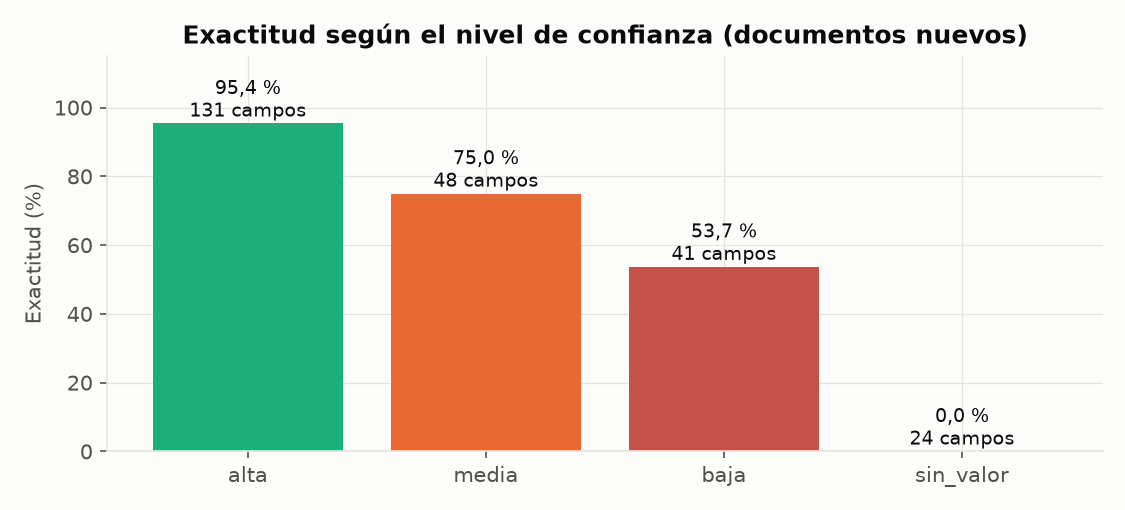

In [9]:
cal = V.calibracion(detalle).round(1)
cal.to_csv(VAL / 'calibracion_confianza.csv', index=False, encoding='utf-8-sig')
display(cal)
fig, ax = plt.subplots(figsize=(7.5, 3.4))
colores = {'alta': AQUA, 'media': NARANJA, 'baja': '#c4514a', 'sin_valor': GRIS}
ax.bar(cal.confianza, cal.exactitud, color=[colores[c] for c in cal.confianza])
for i, r in cal.reset_index(drop=True).iterrows():
    ax.text(i, r.exactitud + 2, f"{es_num(r.exactitud, 1)} %\n{int(r.campos)} campos", ha='center', fontsize=9)
ax.set_ylim(0, 115); ax.set_ylabel('Exactitud (%)'); ax.set_title('Exactitud según el nivel de confianza (documentos nuevos)')
guardar(fig, FIG, 'calibracion_confianza.png'); display(Img(filename=str(FIG / 'calibracion_confianza.png')))

### 5.2 Tiempo de revisión (estimación)
Estimación con supuestos explícitos (modelo de tiempos de teclado KLM; persona que digita a unas 40 palabras por minuto): **digitar** un campo desde la factura, 9 s; **verificar** un valor ya escrito, 2,5 s; **corregir** uno equivocado, 9 s. Es una estimación, no una medición con usuarios: el piloto de la sección 8 debe medirlo. La tabla de sensibilidad muestra cómo cambia el ahorro si verificar tarda la mitad o el doble.

In [10]:
tiempos = V.tiempo_revision(detalle).round(1)
sens = V.sensibilidad_tiempos(detalle).round(1)
tiempos.to_csv(VAL / 'tiempo_revision.csv', index=False, encoding='utf-8-sig')
sens.to_csv(VAL / 'tiempo_revision_sensibilidad.csv', index=False, encoding='utf-8-sig')
display(tiempos); display(sens)

,forma de trabajo,segundos_por_documento,errores_sin_corregir_por_100_documentos,ahorro_vs_manual_%
0,Manual (sin el sistema),22.2,0.0,0.0
1,Revisión completa,11.7,0.0,47.2
2,Revisión guiada por la confianza,7.9,6.1,64.6


,tiempo_verificar_s,segundos_por_documento,ahorro_vs_manual_%
0,1.2,8.6,61.1
1,2.5,11.7,47.2
2,5.0,17.9,19.4


## 6. Escenarios críticos (pruebas de estrés)
Adaptación a imágenes de la tabla del Workshop S5. Cada escenario degrada **las mismas imágenes** de la muestra nueva (`N_ESTRES_POR_BASE` por dataset) y se compara contra esas mismas imágenes sin perturbar.

| Workshop S5 | Aquí | Qué simula |
|---|---|---|
| Ruido en la entrada | Ruido gaussiano σ = 12 y 30 | Poca luz, sensor de gama baja |
| Ruido en la entrada | Desenfoque leve y fuerte | Foto movida |
| Cambio de distribución | 50 % y 30 % de resolución; JPEG calidad 12 | Foto lejana, captura reenviada por mensajería |
| Cambio de distribución | Rotación 6°, sombra lateral | Foto torcida, iluminación desigual |
| Datos faltantes | Falta el 20 % inferior | Comprobante cortado: el pie (totales) no aparece |

En el escenario de recorte el valor correcto a veces ya **no está** en la imagen: ahí lo deseable es que el sistema deje el campo vacío y no invente, así que se mira sobre todo la columna de equivocados.

In [11]:
estres = []
for base in ('sroie', 'wildreceipt'):
    estres += sorted((r for r in muestra if r['dataset'] == base), key=lambda r: r['id'])[:N_ESTRES_POR_BASE]
filas_e, detalles_e = [], {}
inicio = time.perf_counter()
for esc in V.ESCENARIOS:
    filas_esc = estres if esc.clave == 'referencia' else V.filas_perturbadas(estres, esc, PRIV / esc.etiqueta, SEED)
    carpeta = run(filas_esc, CONFIG, VAL / 'escenarios' / esc.etiqueta, SALIDAS / 'cache_ocr_escenarios')
    s = json.loads((carpeta / 'evaluation/summary.json').read_text())
    d = V.detalle_campos(carpeta, NORMALIZACION)
    detalles_e[esc.etiqueta] = d
    filas_e.append({'escenario': esc.nombre, 'simula': esc.simula, **V.resumen_errores(d),
                    'procesados': 100 * s['execution_success_rate']})
    print(f'{esc.nombre:<24} exactitud {100 * d.correct.mean():5.1f} %  ({(time.perf_counter() - inicio) / 60:.0f} min)', flush=True)
escenarios = pd.DataFrame(filas_e)
ref = escenarios.iloc[0].exactitud
escenarios['caida_pp'] = ref - escenarios.exactitud
escenarios['veredicto'] = np.where((escenarios.caida_pp <= CRITERIOS['caida_maxima_pp']) & (escenarios.silenciosos <= CRITERIOS['silenciosos_max'])
                                   & (escenarios.procesados >= CRITERIOS['procesados_min']), 'aceptable', 'falla')
escenarios = escenarios.round(1)
escenarios.to_csv(VAL / 'escenarios_criticos.csv', index=False, encoding='utf-8-sig')
display(escenarios.drop(columns=['simula']))

referencia 10 / 40


referencia 20 / 40


referencia 30 / 40


referencia 40 / 40


Exactitud: 0.8111111111111111
Sin perturbar            exactitud  81.1 %  (4 min)


...

recorte_0.2 20 / 40


recorte_0.2 30 / 40


recorte_0.2 40 / 40


Exactitud: 0.7222222222222222
Falta el 20 % inferior   exactitud  72.2 %  (56 min)


,escenario,campos,exactitud,omisiones,equivocados,silenciosos,procesados,caida_pp,veredicto
0,Sin perturbar,90,81.1,5.6,13.3,2.2,100.0,0.0,aceptable
1,Ruido σ = 12,90,76.7,11.1,12.2,2.2,100.0,4.4,aceptable
2,Ruido σ = 30,90,48.9,33.3,17.8,2.2,100.0,32.2,falla
3,Desenfoque leve,90,42.2,45.6,12.2,2.2,100.0,38.9,falla
4,Desenfoque fuerte,90,17.8,67.8,14.4,1.1,100.0,63.3,falla
5,Mitad de resolución,90,61.1,27.8,11.1,2.2,100.0,20.0,falla
6,30 % de resolución,90,33.3,51.1,15.6,3.3,100.0,47.8,falla
7,JPEG calidad 12,90,61.1,26.7,12.2,1.1,100.0,20.0,falla
8,Rotación 6°,90,53.3,11.1,35.6,6.7,100.0,27.8,falla
9,Sombra lateral,90,72.2,13.3,14.4,2.2,100.0,8.9,aceptable


  figura: escenarios_criticos.png


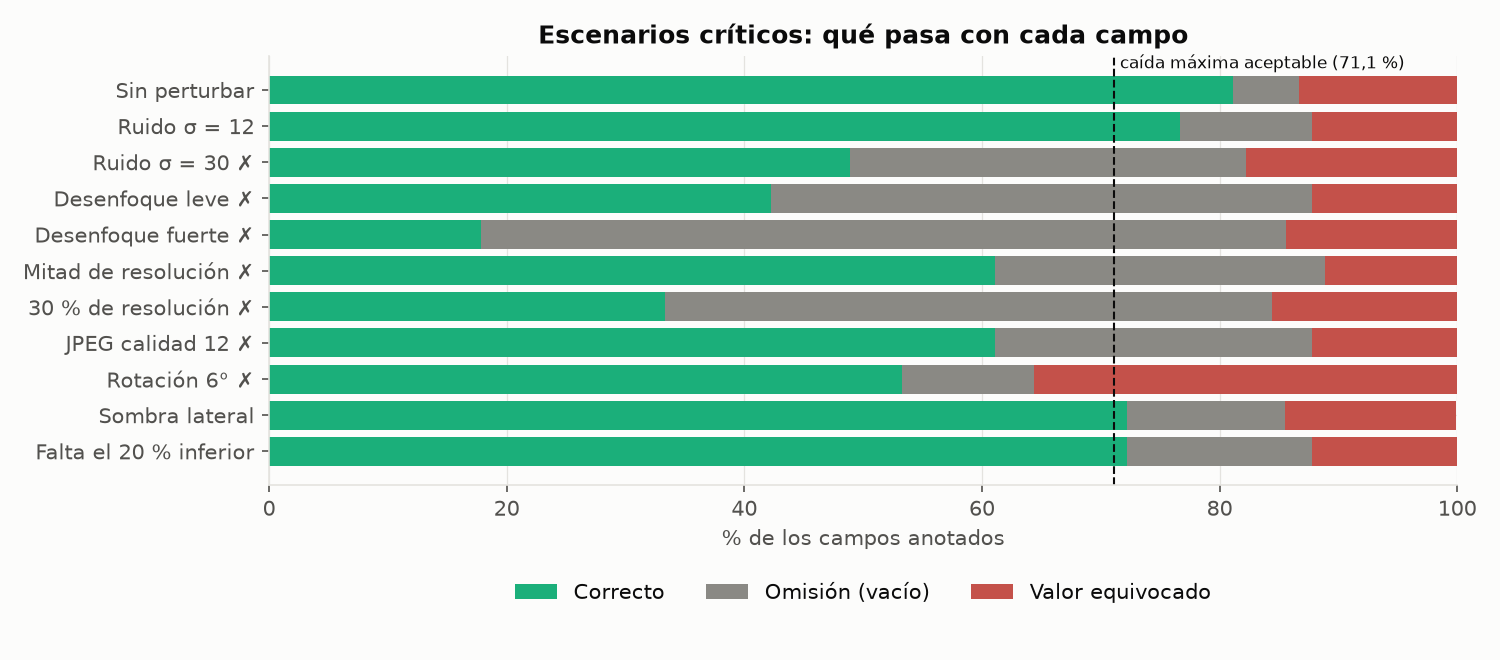

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.4))
orden = escenarios.reset_index(drop=True)
y = np.arange(len(orden))[::-1]
ax.barh(y, orden.exactitud, color=AQUA, label='Correcto')
ax.barh(y, orden.omisiones, left=orden.exactitud, color=GRIS, label='Omisión (vacío)')
ax.barh(y, orden.equivocados, left=orden.exactitud + orden.omisiones, color='#c4514a', label='Valor equivocado')
ax.axvline(ref - CRITERIOS['caida_maxima_pp'], color=TEXTO, ls='--', lw=1)
ax.text(ref - CRITERIOS['caida_maxima_pp'] + .5, len(orden) - .4, f"caída máxima aceptable ({es_num(ref - CRITERIOS['caida_maxima_pp'], 1)} %)", fontsize=8)
ax.set_yticks(y, [f"{e}{' ✗' if v == 'falla' else ''}" for e, v in zip(orden.escenario, orden.veredicto)])
ax.set_xlim(0, 100); ax.set_xlabel('% de los campos anotados'); ax.set_title('Escenarios críticos: qué pasa con cada campo')
ax.legend(loc='lower center', bbox_to_anchor=(.5, -.32), ncol=3)
guardar(fig, FIG, 'escenarios_criticos.png'); display(Img(filename=str(FIG / 'escenarios_criticos.png')))

Así se ven los escenarios, aplicados a un comprobante **sintético** del proyecto (no a una imagen de los datasets):

  figura: escenarios_ejemplo.png


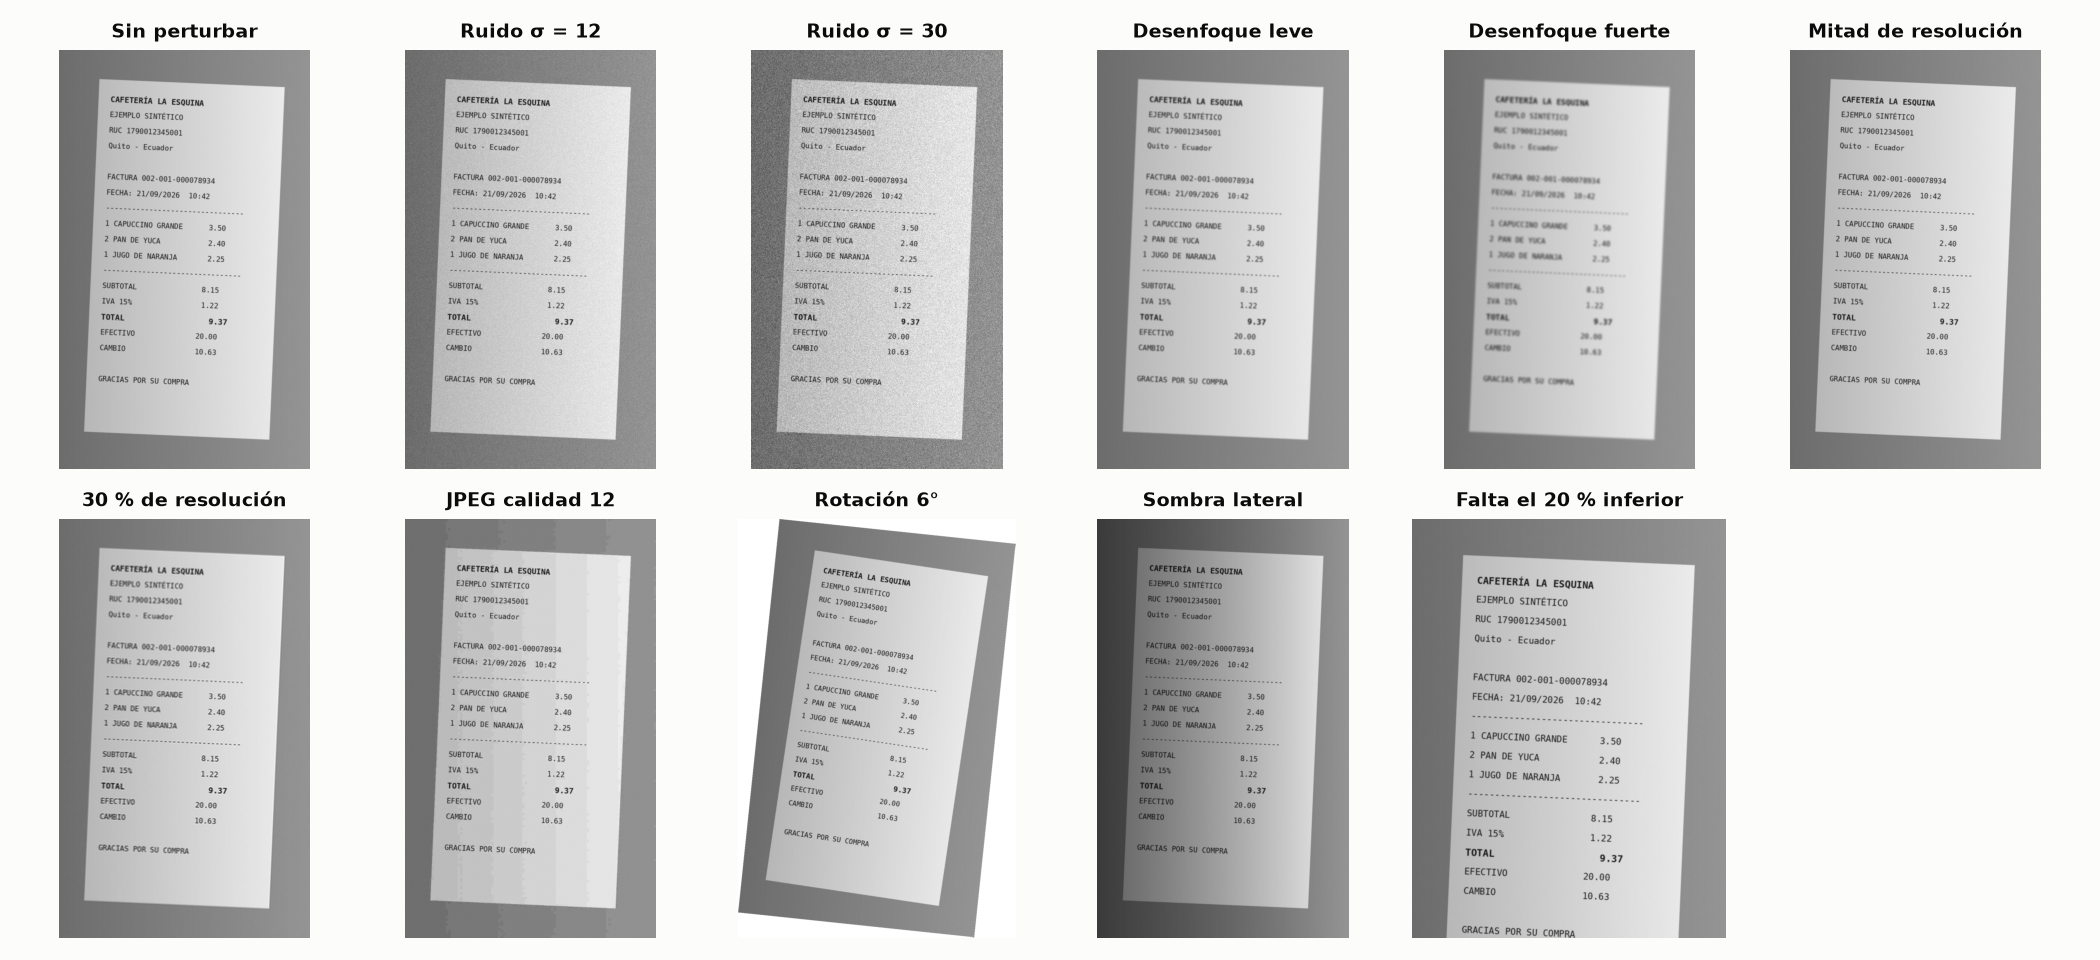

In [13]:
from PIL import Image
ejemplo = Image.open(CODIGO / 'app/assets/ejemplos/recibo_fotografiado.jpg')
fig, ejes = plt.subplots(2, 6, figsize=(14, 6.4))
for ax, esc in zip(ejes.ravel(), V.ESCENARIOS):
    ax.imshow(V.perturbar_imagen(ejemplo, esc, SEED).convert('L'), cmap='gray', vmin=0, vmax=255); ax.set_title(esc.nombre, fontsize=9)
    ax.axis('off')
for ax in ejes.ravel()[len(V.ESCENARIOS):]:
    ax.axis('off')
guardar(fig, FIG, 'escenarios_ejemplo.png'); display(Img(filename=str(FIG / 'escenarios_ejemplo.png')))

## 7. Equidad: ¿a quién le funciona peor?
En este sistema no hay grupos de personas en los datos, pero sí de **quién captura** la factura: escáner (SROIE) o celular (WildReceipt), imagen pequeña o grande, y calidad de la lectura. Se mide por subgrupo la exactitud, las omisiones, los errores silenciosos y la **carga de revisión** (campos sin confianza alta por documento).

In [14]:
cer = pd.read_csv(NUEVOS / 'evaluation/cer.csv', encoding='utf-8-sig')[['id', 'cer']]
tam = pd.DataFrame([{'id': r['id'], 'mpx': (r['width'] or 0) * (r['height'] or 0) / 1e6} for r in muestra])
d = detalle.merge(tam, on='id', how='left').merge(cer, on='id', how='left')
docs = d.drop_duplicates('id').set_index('id')
terc_tam = pd.qcut(docs.mpx.rank(method='first'), 3, labels=['pequeña', 'mediana', 'grande'])
terc_cer = pd.qcut(docs.cer.rank(method='first'), 3, labels=['OCR limpio', 'OCR medio', 'OCR con muchos errores'])
grupos = {'captura': lambda x: x.dataset.map({'sroie': 'escáner (SROIE)', 'wildreceipt': 'celular (WildReceipt)'}),
          'tamaño de imagen': lambda x: x.id.map(terc_tam), 'calidad del OCR': lambda x: x.id.map(terc_cer)}
equidad = V.por_subgrupo(d, grupos)
carga = {f: d.groupby(g(d)).apply(lambda x: (x.confianza != 'alta').groupby(x.id).sum().mean()) for f, g in grupos.items()}
equidad['campos_a_revisar_por_doc'] = [carga[f].get(g) for f, g in zip(equidad.factor, equidad.grupo)]
equidad = equidad.round(2)
equidad.to_csv(VAL / 'equidad_subgrupos.csv', index=False, encoding='utf-8-sig')
display(equidad)

,factor,grupo,documentos,campos,exactitud,omisiones,equivocados,silenciosos,campos_a_revisar_por_doc
0,captura,celular (WildReceipt),49,144,67.36,15.28,17.36,2.78,1.63
1,captura,escáner (SROIE),50,100,86.00,2.00,12.00,2.00,0.66
2,tamaño de imagen,pequeña,33,98,66.33,13.27,20.41,3.06,1.70
3,tamaño de imagen,mediana,33,77,74.03,12.99,12.99,1.30,1.09
4,tamaño de imagen,grande,33,69,88.41,1.45,10.14,2.90,0.64
5,calidad del OCR,OCR limpio,33,69,89.86,1.45,8.70,2.90,0.52
6,calidad del OCR,OCR medio,33,78,80.77,5.13,14.10,1.28,0.94
7,calidad del OCR,OCR con muchos errores,33,97,59.79,19.59,20.62,3.09,1.97


## 8. Plan de validación en contexto real
Cada etapa tiene un umbral de avance y una condición de retroceso, como pide el Workshop S5.

| Etapa | Cómo | Umbral para avanzar | Retroceso (rollback) |
|---|---|---|---|
| 1. Offline | Test oficial y documentos nunca revisados (notebooks 05 y 06) | ≥ 70 % por campo, ≥ 90 % procesados | No publicar la versión |
| 2. Simulación | Escenarios críticos de la sección 6 | Caída ≤ 10 puntos y silenciosos ≤ 5 % en los escenarios esperables | Documentar el escenario como fuera de alcance o mejorar el preprocesamiento |
| 3. Sombra | El sistema lee las facturas de un mes mientras el personal sigue digitando; se comparan ambos | Exactitud con facturas ecuatorianas ≥ 70 % y errores silenciosos ≤ 5 % | Volver a revisión completa y ajustar reglas solo con documentos de desarrollo |
| 4. Piloto | Una persona usa la interfaz con revisión completa durante dos semanas | Ahorro de tiempo medido ≥ 30 % sin aumentar las correcciones posteriores | Volver a la digitación manual |
| 5. Monitoreo | Registro semanal de campos corregidos, alertas y tiempo por factura | Tasa de corrección estable (± 5 puntos) | Si sube, revisar formatos nuevos de emisores y reevaluar |

## 9. Guardar resultados
El ZIP reúne las tablas y figuras (en el repositorio, en `results/metrics/validacion/` y `results/figures/validacion/`). Las imágenes perturbadas, las predicciones y la muestra quedan fuera.

In [15]:
resumen = {'plan': {k: plan[k] for k in ('criterios', 'revision_codigo', 'fecha_utc')}, 'muestra': plan_muestra,
           'nuevos': cumple, 'por_documento': por_documento, 'composicion': composicion,
           'calibracion': cal.to_dict(orient='records'), 'tiempos': tiempos.to_dict(orient='records'),
           'escenarios': escenarios.to_dict(orient='records')}
write_json(VAL / 'resumen_validacion.json', resumen)
archivo = SALIDAS / (VAL.name + '.zip')
excluir = ('predictions.jsonl', 'evaluation_manifest.jsonl', 'errors.csv')
with zipfile.ZipFile(archivo, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in VAL.rglob('*'):
        if p.is_file() and 'documento_privado' not in p.parts and p.name not in excluir:
            z.write(p, p.relative_to(VAL))
print('ZIP:', archivo)
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    pass

ZIP: /home/runner/work/Document-Scanner/Document-Scanner/outputs/experimentos/notebooks/validacion_20261024T220153Z.zip


## 10. Conclusiones
_Se completan con los resultados de la ejecución._